# Laboratorio — Mini-GPT a nivel de carácter y estrategias de muestreo
**CC3092 Deep Learning — Universidad del Valle de Guatemala**

**Entrega parcial: Task 1 y Task 2**

Este notebook extiende el Mini-GPT implementado desde cero en la Semana 6 (Proyecto 1). Se reutilizan exactamente los mismos componentes (embeddings + codificación posicional sinusoidal, atención multi-cabeza con $W_Q, W_K, W_V, W_O$ escrita a mano, máscara causal con $-\infty$, LayerNorm manual, FFN con ReLU y conexiones residuales *post-LN*). Los cambios respecto a la Semana 6 son los que exige el laboratorio:

| | Semana 6 | Este laboratorio |
|---|---|---|
| Tokenización | palabras (SST-2) | caracteres (tiny_shakespeare) |
| Vocabulario | 432 | 65 |
| Contexto | 14 | `block_size = 128` |
| `d_model` / cabezas / capas | 32 / 2 / 1 | 128 / 4 / 3 |
| Entrenamiento | una oración a la vez | batches de 64 secuencias |
| Muestreo | multinomial con temperatura | greedy, top-k y top-p implementados desde cero |

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import math, random, time, urllib.request, os, json
from collections import Counter
import numpy as np
import matplotlib.pyplot as plt

SEED = 42
torch.manual_seed(SEED); random.seed(SEED); np.random.seed(SEED)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'PyTorch {torch.__version__} | device: {device}')

PyTorch 2.13.0+cpu | device: cpu


## Task 1.1 — Dataset y pipeline a nivel de carácter

Se descarga `tiny_shakespeare`, se construye el vocabulario de caracteres únicos y los dos mappings (`stoi`: carácter → índice, `itos`: índice → carácter). El texto completo se codifica como una secuencia de enteros y se divide 90 % / 10 % respetando el orden temporal: el conjunto de validación es el último 10 % del texto, de modo que el modelo nunca ve durante el entrenamiento el texto que sigue a lo que se evalúa.

In [2]:
URL = 'https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt'
if not os.path.exists('input.txt'):
    urllib.request.urlretrieve(URL, 'input.txt')
with open('input.txt', encoding='utf-8') as f:
    text = f.read()
print(f'Caracteres en el corpus: {len(text):,}')
print('-' * 40)
print(text[:250])

Caracteres en el corpus: 1,115,394
----------------------------------------
First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.



In [3]:
# Vocabulario: conjunto de caracteres unicos, ordenado para que el mapping sea determinista
chars = sorted(set(text))
vocab_size = len(chars)
assert vocab_size == 65, f'El vocabulario debe tener 65 caracteres, tiene {vocab_size}'

# Mappings bidireccionales caracter <-> indice entero
stoi = {ch: i for i, ch in enumerate(chars)}
itos = {i: ch for ch, i in stoi.items()}

def encode(s):
    # str -> lista de indices
    return [stoi[c] for c in s]

def decode(ids):
    # lista de indices -> str
    return ''.join(itos[int(i)] for i in ids)

print(f'vocab_size = {vocab_size}')
print('Vocabulario:', repr(''.join(chars)))
assert decode(encode('ROMEO: Hello!')) == 'ROMEO: Hello!'

# Texto completo como secuencia de indices
data = torch.tensor(encode(text), dtype=torch.long)

# Division 90/10 respetando el orden temporal (sin barajar)
n_train = int(0.9 * len(data))
train_data = data[:n_train]
val_data   = data[n_train:]
print(f'Train: {len(train_data):,} tokens | Val: {len(val_data):,} tokens')

vocab_size = 65
Vocabulario: "\n !$&',-.3:;?ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyz"
Train: 1,003,854 tokens | Val: 111,540 tokens


### Hiperparámetros

Se usan los mínimos del enunciado. `d_ff` no está especificado; se usa $d_{ff} = 4\,d_{model}$, la misma proporción del Transformer original ($512 \to 2048$).

In [4]:
block_size = 128          # longitud de contexto T
d_model    = 128          # dimension de los embeddings
n_heads    = 4            # cabezas de atencion
n_layers   = 3            # bloques Transformer apilados
batch_size = 64
lr         = 3e-4
epochs     = 10

d_k  = d_model // n_heads # dimension por cabeza = 32
d_ff = 4 * d_model        # dimension interna del FFN = 512

### Generación de batches

Para un inicio $s$, la entrada es $x = (c_s, \dots, c_{s+T-1})$ y el objetivo es la misma ventana desplazada un paso hacia el futuro, $y = (c_{s+1}, \dots, c_{s+T})$. Así, en cada posición $t$ el modelo debe predecir $y_t = x_{t+1}$, y una sola secuencia aporta $T = 128$ ejemplos de entrenamiento.

**Definición de época.** Una época recorre el conjunto de entrenamiento completo en ventanas no traslapadas de longitud `block_size`, barajadas. En cada época se aplica un desplazamiento inicial aleatorio en $[0, T)$ para que las fronteras entre ventanas no caigan siempre en los mismos caracteres. Con ~1 M de caracteres esto da ~7,840 secuencias y 122 batches por época (1,220 pasos de optimización en total).

In [5]:
def get_batch(split_data, starts):
    # Construye (x, y) a partir de una lista de posiciones de inicio.
    # y es x desplazada un paso: y[:, t] = x[:, t+1]
    x = torch.stack([split_data[s     : s + block_size    ] for s in starts])
    y = torch.stack([split_data[s + 1 : s + block_size + 1] for s in starts])
    return x.to(device), y.to(device)

def epoch_batches(split_data):
    # Ventanas no traslapadas, con desplazamiento aleatorio y orden barajado
    offset = random.randint(0, block_size - 1)
    starts = list(range(offset, len(split_data) - block_size - 1, block_size))
    random.shuffle(starts)
    for i in range(0, len(starts) - batch_size + 1, batch_size):
        yield get_batch(split_data, starts[i:i + batch_size])

# Verificacion: el objetivo es la entrada desplazada un paso
xb, yb = get_batch(train_data, [0, 1000])
print('x:', repr(decode(xb[0, :40])))
print('y:', repr(decode(yb[0, :40])))
assert torch.equal(xb[:, 1:], yb[:, :-1])
print(f'Batches por epoca: {sum(1 for _ in epoch_batches(train_data))}')

x: 'First Citizen:\nBefore we proceed any fur'
y: 'irst Citizen:\nBefore we proceed any furt'
Batches por epoca: 122


## Modelo: Mini-GPT de la Semana 6 generalizado

Los componentes son los mismos del Proyecto 1. Lo único que cambia en el código es que ahora todo opera sobre tensores con una dimensión de batch $(B, T, d)$ y que se apilan `n_layers` bloques en lugar de uno.

**Codificación posicional** (Vaswani et al., 2017):
$$PE(t, 2i) = \sin\!\left(\frac{t}{10000^{2i/d}}\right), \qquad PE(t, 2i+1) = \cos\!\left(\frac{t}{10000^{2i/d}}\right)$$

**Atención con máscara causal**, por cabeza:
$$\text{Attention}(Q,K,V) = \text{softmax}\!\left(\frac{QK^\top}{\sqrt{d_k}} + M\right)V, \qquad M_{ij} = \begin{cases} 0 & j \le i \\ -\infty & j > i \end{cases}$$

**Bloque** (post-LN, igual que en la Semana 6):
$$x' = \text{LN}(x + \text{MHA}(x)), \qquad x'' = \text{LN}(x' + \text{FFN}(x')), \qquad \text{FFN}(x) = \text{ReLU}(xW_1 + b_1)W_2 + b_2$$

**Inicialización.** En la Semana 6 los pesos se inicializaban con $\mathcal{N}(0, 0.1^2)$, adecuado para $d_{model}=32$. Con $d_{model}=128$ se usa $\mathcal{N}(0, 0.02^2)$ para las matrices (la convención de GPT-2), de modo que los logits iniciales sean casi uniformes y la pérdida inicial quede cerca de $\ln 65 \approx 4.17$. Los embeddings se inicializan con varianza 1 para que su escala sea comparable a la de la codificación posicional (cuyos valores están en $[-1, 1]$); si fueran mucho más pequeños, al inicio el modelo vería casi solo la posición y no el carácter.

In [6]:
def layer_norm(x, gamma, beta, eps=1e-5):
    # LN(x) = gamma * (x - mu) / sqrt(sigma^2 + eps) + beta, sobre la ultima dimension
    # (misma implementacion manual de la Semana 6, varianza con unbiased=False)
    mean = x.mean(-1, keepdim=True)
    var  = x.var(-1, unbiased=False, keepdim=True)
    return gamma * (x - mean) / torch.sqrt(var + eps) + beta

def make_positional_encoding(max_len, d_model):
    # PE(t,2i) = sin(t / 10000^(2i/d)),  PE(t,2i+1) = cos(t / 10000^(2i/d))
    pe  = torch.zeros(max_len, d_model)
    pos = torch.arange(max_len).unsqueeze(1).float()
    div = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))
    pe[:, 0::2] = torch.sin(pos * div)
    pe[:, 1::2] = torch.cos(pos * div)
    return pe

INIT_STD = 0.02

class TransformerBlock(nn.Module):
    # Un bloque decoder: masked multi-head self-attention + FFN, cada uno con residual + LayerNorm.
    # Mismos parametros que el MiniGPT de la Semana 6.
    def __init__(self, d_model, n_heads, d_ff, block_size):
        super().__init__()
        self.d_model, self.n_heads, self.d_k = d_model, n_heads, d_model // n_heads
        # Proyecciones de atencion
        self.WQ = nn.Parameter(torch.randn(d_model, d_model) * INIT_STD)
        self.WK = nn.Parameter(torch.randn(d_model, d_model) * INIT_STD)
        self.WV = nn.Parameter(torch.randn(d_model, d_model) * INIT_STD)
        self.WO = nn.Parameter(torch.randn(d_model, d_model) * INIT_STD)
        # Primer LayerNorm
        self.gamma1 = nn.Parameter(torch.ones(d_model))
        self.beta1  = nn.Parameter(torch.zeros(d_model))
        # Feed-forward
        self.W1    = nn.Parameter(torch.randn(d_model, d_ff) * INIT_STD)
        self.bias1 = nn.Parameter(torch.zeros(d_ff))
        self.W2    = nn.Parameter(torch.randn(d_ff, d_model) * INIT_STD)
        self.bias2 = nn.Parameter(torch.zeros(d_model))
        # Segundo LayerNorm
        self.gamma2 = nn.Parameter(torch.ones(d_model))
        self.beta2  = nn.Parameter(torch.zeros(d_model))
        # Mascara causal: True en el triangulo superior (posiciones futuras j > i)
        self.register_buffer('causal_mask',
                             torch.triu(torch.ones(block_size, block_size), diagonal=1).bool())

    def masked_self_attention(self, x):
        B, T, _ = x.shape
        # 1. Proyecciones Q = xW_Q, K = xW_K, V = xW_V  -> (B, T, d_model)
        # 2. Separar cabezas -> (B, h, T, d_k)
        Q = (x @ self.WQ).view(B, T, self.n_heads, self.d_k).transpose(1, 2)
        K = (x @ self.WK).view(B, T, self.n_heads, self.d_k).transpose(1, 2)
        V = (x @ self.WV).view(B, T, self.n_heads, self.d_k).transpose(1, 2)
        # 3. Scores escalados: QK^T / sqrt(d_k) -> (B, h, T, T)
        scores = Q @ K.transpose(-2, -1) / math.sqrt(self.d_k)
        # 4. Mascara causal M: posiciones futuras = -inf, asi exp(-inf) = 0 tras el softmax
        scores = scores.masked_fill(self.causal_mask[:T, :T], float('-inf'))
        # 5. Softmax por fila -> pesos de atencion alpha_ij
        attn_w = torch.softmax(scores, dim=-1)
        # 6. Suma ponderada de values y concatenacion de cabezas -> (B, T, d_model)
        out = (attn_w @ V).transpose(1, 2).reshape(B, T, self.d_model)
        # 7. Proyeccion de salida W_O
        return out @ self.WO

    def feed_forward(self, x):
        # FFN(x) = ReLU(x W1 + b1) W2 + b2
        return torch.relu(x @ self.W1 + self.bias1) @ self.W2 + self.bias2

    def forward(self, x):
        # x' = LN(x + MHA(x));  x'' = LN(x' + FFN(x'))
        x = layer_norm(x + self.masked_self_attention(x), self.gamma1, self.beta1)
        x = layer_norm(x + self.feed_forward(x), self.gamma2, self.beta2)
        return x


class MiniGPT(nn.Module):
    # Transformer decoder-only a nivel de caracter: embeddings + PE -> N bloques -> cabeza LM
    def __init__(self, vocab_size, d_model, n_heads, n_layers, d_ff, block_size):
        super().__init__()
        self.block_size = block_size
        self.E = nn.Parameter(torch.randn(vocab_size, d_model))      # tabla de embeddings
        self.blocks = nn.ModuleList(
            [TransformerBlock(d_model, n_heads, d_ff, block_size) for _ in range(n_layers)])
        self.Wlm = nn.Parameter(torch.randn(d_model, vocab_size) * INIT_STD)  # cabeza LM
        self.blm = nn.Parameter(torch.zeros(vocab_size))
        self.register_buffer('PE', make_positional_encoding(block_size, d_model))

    def forward(self, idx):
        # idx: (B, T) indices -> logits: (B, T, vocab_size)
        T = idx.shape[1]
        x = self.E[idx] + self.PE[:T]          # x_t = E[c_t] + PE[t]
        for block in self.blocks:
            x = block(x)
        return x @ self.Wlm + self.blm          # z_t = x_t W_lm + b_lm  (logits crudos)

torch.manual_seed(SEED)
model = MiniGPT(vocab_size, d_model, n_heads, n_layers, d_ff, block_size).to(device)
n_params = sum(p.numel() for p in model.parameters())
print(f'Parametros entrenables: {n_params:,}')

Parametros entrenables: 609,985


In [7]:
# Verificaciones antes de entrenar
xb, yb = get_batch(train_data, [0, 500, 1000, 1500])
with torch.no_grad():
    logits = model(xb)
    loss0 = F.cross_entropy(logits.view(-1, vocab_size), yb.view(-1)).item()
print(f'logits: {tuple(logits.shape)}')
print(f'Perdida inicial: {loss0:.4f}  (referencia ln(65) = {math.log(vocab_size):.4f})')

# Causalidad: cambiar el ultimo caracter NO debe alterar los logits de posiciones anteriores
x_mod = xb.clone(); x_mod[:, -1] = (x_mod[:, -1] + 1) % vocab_size
with torch.no_grad():
    diff = (model(x_mod)[:, :-1] - logits[:, :-1]).abs().max().item()
print(f'Max cambio en posiciones pasadas al modificar el futuro: {diff:.2e}  (debe ser 0)')
assert diff < 1e-5

logits: (4, 128, 65)
Perdida inicial: 4.1979  (referencia ln(65) = 4.1744)
Max cambio en posiciones pasadas al modificar el futuro: 0.00e+00  (debe ser 0)


## Task 1.2 — Entrenamiento y perplejidad de validación

La pérdida es la cross-entropy promedio sobre todas las posiciones de todas las secuencias del batch:
$$\mathcal{L} = -\frac{1}{BT}\sum_{b=1}^{B}\sum_{t=1}^{T} \log p_\theta\!\left(y_{b,t} \mid x_{b,1}, \dots, x_{b,t}\right)$$

Al terminar cada época se evalúa sobre todo el conjunto de validación (ventanas no traslapadas), acumulando la suma de las pérdidas por token y dividiendo entre el número total de tokens $N$. La perplejidad es exactamente la fórmula del enunciado:
$$\text{PPL} = \exp\!\left(\frac{1}{N}\sum_{t=1}^{N}\mathcal{L}_t\right)$$

In [8]:
@torch.no_grad()
def evaluate(split_data):
    # Devuelve (perdida media por token, N). Suma CE token a token (reduction='sum') y divide entre N.
    model.eval()
    starts = list(range(0, len(split_data) - block_size - 1, block_size))
    total_loss, total_tokens = 0.0, 0
    for i in range(0, len(starts), batch_size):
        x, y = get_batch(split_data, starts[i:i + batch_size])
        logits = model(x)
        total_loss   += F.cross_entropy(logits.view(-1, vocab_size), y.view(-1), reduction='sum').item()
        total_tokens += y.numel()
    model.train()
    return total_loss / total_tokens, total_tokens

torch.manual_seed(SEED); random.seed(SEED)
model = MiniGPT(vocab_size, d_model, n_heads, n_layers, d_ff, block_size).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=lr)

history = {'train': [], 'val': []}
t0 = time.time()
for epoch in range(1, epochs + 1):
    model.train()
    running, n_batches = 0.0, 0
    for x, y in epoch_batches(train_data):
        logits = model(x)
        loss = F.cross_entropy(logits.view(-1, vocab_size), y.view(-1))
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        running += loss.item(); n_batches += 1
    train_loss = running / n_batches
    val_loss, N_val = evaluate(val_data)
    history['train'].append(train_loss); history['val'].append(val_loss)
    print(f'Epoca {epoch:2d} | train {train_loss:.4f} | val {val_loss:.4f} | '
          f'PPL val {math.exp(val_loss):6.3f} | {time.time() - t0:5.0f}s')

torch.save(model.state_dict(), 'minigpt_char.pt')

Epoca  1 | train 3.0439 | val 2.6264 | PPL val 13.824 |    31s
Epoca  2 | train 2.5284 | val 2.4454 | PPL val 11.535 |    63s
Epoca  3 | train 2.3783 | val 2.3236 | PPL val 10.212 |    94s
Epoca  4 | train 2.2714 | val 2.2457 | PPL val  9.447 |   125s
Epoca  5 | train 2.2007 | val 2.1981 | PPL val  9.008 |   157s
Epoca  6 | train 2.1354 | val 2.1353 | PPL val  8.460 |   191s
Epoca  7 | train 2.0773 | val 2.0929 | PPL val  8.108 |   225s
Epoca  8 | train 2.0274 | val 2.0636 | PPL val  7.875 |   257s
Epoca  9 | train 1.9837 | val 2.0304 | PPL val  7.617 |   288s
Epoca 10 | train 1.9405 | val 2.0007 | PPL val  7.395 |   318s


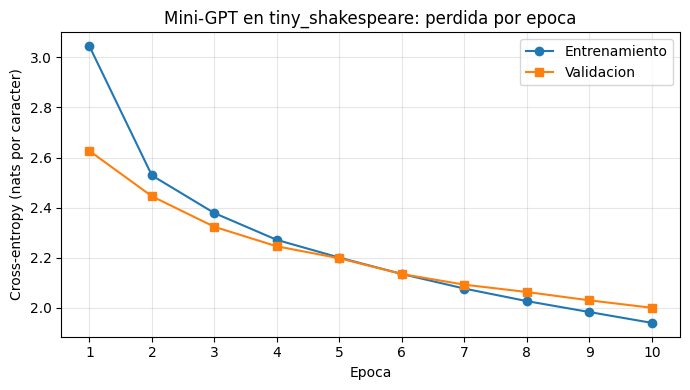

Tokens de validacion evaluados N = 111,488
Perdida media de validacion = 2.0007 nats
PERPLEJIDAD DE VALIDACION = 7.395
Dentro del rango esperado [3.5, 8.0]: True


In [9]:
ep = range(1, epochs + 1)
plt.figure(figsize=(7, 4))
plt.plot(ep, history['train'], 'o-', label='Entrenamiento')
plt.plot(ep, history['val'],   's-', label='Validacion')
plt.xlabel('Epoca'); plt.ylabel('Cross-entropy (nats por caracter)')
plt.title('Mini-GPT en tiny_shakespeare: perdida por epoca')
plt.xticks(list(ep)); plt.grid(alpha=0.3); plt.legend(); plt.tight_layout()
plt.savefig('curva_perdida.png', dpi=150)
plt.show()

val_loss, N_val = evaluate(val_data)
val_ppl = math.exp(val_loss)
print(f'Tokens de validacion evaluados N = {N_val:,}')
print(f'Perdida media de validacion = {val_loss:.4f} nats')
print(f'PERPLEJIDAD DE VALIDACION = {val_ppl:.3f}')
print('Dentro del rango esperado [3.5, 8.0]:', 3.5 <= val_ppl <= 8.0)

**Resultado del Task 1.2.** La perplejidad de validación es **7.395** (pérdida media de 2.0007 nats por carácter sobre $N = 111{,}488$ tokens), dentro del rango esperado de 3.5 a 8.0. Una perplejidad de 7.4 significa que, en promedio, el modelo está tan indeciso como si eligiera uniformemente entre unos 7 caracteres, frente a 65 de un modelo que no aprendió nada ($\ln 65 = 4.17$ nats, perplejidad 65).

Ambas curvas siguen bajando en la época 10, así que el modelo no ha convergido: 10 épocas son apenas 1,220 pasos de optimización con `lr = 3e-4`. La pérdida de validación queda solo 0.06 nats por encima de la de entrenamiento (2.001 vs 1.941), de modo que no hay sobreajuste; con más épocas la perplejidad seguiría bajando.

## Task 1.3 — Funciones de muestreo desde cero

Las tres funciones reciben los logits crudos $z \in \mathbb{R}^{65}$ del último paso y devuelven el índice del siguiente carácter. Para que el muestreo también sea explícito, no se usa `torch.multinomial`: `sample_from_probs` implementa el método de la transformada inversa. Se toma $u \sim \mathcal{U}(0,1)$ y se elige el primer índice $i$ tal que la probabilidad acumulada $F_i = \sum_{j \le i} p_j$ cumple $F_i > u$; así $P(\text{elegir } i) = F_i - F_{i-1} = p_i$.

* **Greedy:** $\hat{w} = \arg\max_i z_i$. Como softmax es monótona, es lo mismo que el argmax de las probabilidades.
* **Top-k con temperatura:** $z/\tau$, se conservan los $k$ mayores (los demás $\to -\infty$, cuya probabilidad es exactamente $e^{-\infty}=0$), softmax y muestreo.
* **Top-p (nucleus) con temperatura:** $z/\tau$, softmax, orden descendente, se incluyen tokens hasta que la probabilidad acumulada supere $p$ (el token que cruza el umbral sí se incluye, así que el núcleo nunca queda vacío), renormalización y muestreo.

In [10]:
def softmax(z):
    # p_i = exp(z_i - max z) / sum_j exp(z_j - max z). Restar el maximo no cambia el resultado
    # pero evita overflow; exp(-inf) = 0 exactamente.
    z = z - z.max()
    e = torch.exp(z)
    return e / e.sum()

def sample_from_probs(probs):
    # Muestreo por transformada inversa: primer i con F_i > u, u ~ U(0,1)
    cdf = torch.cumsum(probs, dim=0)
    u = torch.rand(1, device=probs.device) * cdf[-1]       # * cdf[-1] protege contra redondeo
    idx = int(torch.searchsorted(cdf, u, right=True).item())
    return min(idx, len(probs) - 1)

def greedy_sample(logits):
    # w = argmax_i z_i. Determinista, sin aleatoriedad.
    return int(torch.argmax(logits).item())

def top_k_sample(logits, k, tau=1.0):
    # 1) z/tau  2) conservar los k mayores, el resto = -inf  3) softmax  4) muestrear
    z = logits / tau
    k = min(k, z.numel())
    kth_value = torch.topk(z, k).values[-1]                 # k-esimo mayor logit
    z = torch.where(z >= kth_value, z, torch.full_like(z, float('-inf')))
    return sample_from_probs(softmax(z))

def top_p_sample(logits, p, tau=1.0):
    # 1) z/tau  2) softmax  3) ordenar descendente  4) incluir hasta que la acumulada supere p
    # 5) renormalizar  6) muestrear
    probs = softmax(logits / tau)
    sorted_probs, sorted_idx = torch.sort(probs, descending=True)
    cum = torch.cumsum(sorted_probs, dim=0)
    # Un token entra si la masa acumulada ANTES de el aun no supera p.
    # Asi se incluye el token que cruza el umbral y el primero siempre entra.
    keep = (cum - sorted_probs) < p
    nucleus = sorted_probs * keep
    nucleus = nucleus / nucleus.sum()                       # renormalizar
    return int(sorted_idx[sample_from_probs(nucleus)].item())

def nucleus_size(logits, p, tau=1.0):
    # Cuantos tokens quedan en el nucleo (para el analisis del Task 2.2)
    probs = softmax(logits / tau)
    sp, _ = torch.sort(probs, descending=True)
    return int(((torch.cumsum(sp, 0) - sp) < p).sum().item())

In [11]:
# Pruebas unitarias con una distribucion conocida
torch.manual_seed(0)
z_test = torch.log(torch.tensor([0.50, 0.25, 0.15, 0.07, 0.03]))

assert greedy_sample(z_test) == 0

# top-k con k=2 solo puede devolver los indices 0 o 1
draws = Counter(top_k_sample(z_test, k=2, tau=1.0) for _ in range(20000))
assert set(draws) <= {0, 1}
print('top-k (k=2) frecuencias:', {i: round(c / 20000, 3) for i, c in sorted(draws.items())},
      '| teorico: {0: 0.667, 1: 0.333}')

# top-p con p=0.70: acumuladas 0.50, 0.75 -> nucleo {0, 1}; con p=0.80: {0, 1, 2}
assert nucleus_size(z_test, 0.70) == 2 and nucleus_size(z_test, 0.80) == 3
draws = Counter(top_p_sample(z_test, p=0.70, tau=1.0) for _ in range(20000))
assert set(draws) <= {0, 1}
print('top-p (p=0.7) frecuencias:', {i: round(c / 20000, 3) for i, c in sorted(draws.items())},
      '| teorico: {0: 0.667, 1: 0.333}')

# sample_from_probs reproduce la distribucion original
draws = Counter(sample_from_probs(softmax(z_test)) for _ in range(50000))
print('transformada inversa:   ', [round(draws[i] / 50000, 3) for i in range(5)],
      '| teorico: [0.5, 0.25, 0.15, 0.07, 0.03]')
print('Todas las pruebas pasaron.')

top-k (k=2) frecuencias: {0: 0.666, 1: 0.334} | teorico: {0: 0.667, 1: 0.333}
top-p (p=0.7) frecuencias: {0: 0.664, 1: 0.336} | teorico: {0: 0.667, 1: 0.333}
transformada inversa:    [0.5, 0.252, 0.149, 0.069, 0.03] | teorico: [0.5, 0.25, 0.15, 0.07, 0.03]
Todas las pruebas pasaron.


## Task 2.1 — Función `generate` y muestras

`generate` codifica el prompt, y en cada paso: (1) recorta el contexto a los últimos `block_size` caracteres, porque la codificación posicional y la máscara solo existen para $T \le 128$; (2) hace el forward; (3) toma los logits de la última posición, que es la distribución $p(c_{t+1} \mid c_{\le t})$; (4) elige el siguiente carácter con la estrategia indicada y lo concatena al contexto (generación autoregresiva).

Cada muestra usa una semilla fija distinta para que los resultados sean reproducibles.

In [12]:
STRATEGIES = {'greedy': greedy_sample, 'top_k': top_k_sample, 'top_p': top_p_sample}

@torch.no_grad()
def generate(prompt, max_new_tokens, strategy, return_logits=False, **kwargs):
    # Genera max_new_tokens caracteres a partir de prompt.
    # strategy in {'greedy','top_k','top_p'}; kwargs = k, p, tau segun la estrategia.
    model.eval()
    sampler = STRATEGIES[strategy]
    idx = torch.tensor([encode(prompt)], dtype=torch.long, device=device)
    step_logits = []
    for _ in range(max_new_tokens):
        idx_cond = idx[:, -block_size:]              # contexto maximo = block_size
        logits = model(idx_cond)[0, -1, :]           # logits crudos del siguiente caracter
        if return_logits:
            step_logits.append(logits.cpu())
        next_id = sampler(logits, **kwargs)
        idx = torch.cat([idx, torch.tensor([[next_id]], device=device)], dim=1)
    out = decode(idx[0].tolist())
    return (out, step_logits) if return_logits else out

CONFIGS = {
    'A': ('greedy', {}),
    'B': ('top_k', {'k': 5,  'tau': 0.7}),
    'C': ('top_k', {'k': 50, 'tau': 1.0}),
    'D': ('top_p', {'p': 0.70, 'tau': 0.7}),
    'E': ('top_p', {'p': 0.95, 'tau': 1.0}),
}
PROMPT, N_SAMPLES, N_CHARS = 'ROMEO:', 5, 200

samples, sample_logits = {}, {}
for cfg, (strategy, kw) in CONFIGS.items():
    samples[cfg], sample_logits[cfg] = [], []
    for s in range(N_SAMPLES):
        torch.manual_seed(1000 + s)
        txt, lg = generate(PROMPT, N_CHARS, strategy, return_logits=True, **kw)
        samples[cfg].append(txt); sample_logits[cfg].append(lg)

with open('muestras.json', 'w', encoding='utf-8') as f:
    json.dump(samples, f, ensure_ascii=False, indent=2)

In [13]:
for cfg, (strategy, kw) in CONFIGS.items():
    print('=' * 72)
    print(f'CONFIGURACION {cfg}: {strategy} {kw}')
    print('=' * 72)
    for s, txt in enumerate(samples[cfg], 1):
        print(f'--- Muestra {cfg}{s} ---')
        print(txt)
        print()

CONFIGURACION A: greedy {}
--- Muestra A1 ---
ROMEO:
And the the sould the the sould the thee thee thee thee
The so the the so the sone the the so thee thee thee
The sord the the sheard and the thee thee thee thee thee thee thee thee thee thee thee the

--- Muestra A2 ---
ROMEO:
And the the sould the the sould the thee thee thee thee
The so the the so the sone the the so thee thee thee
The sord the the sheard and the thee thee thee thee thee thee thee thee thee thee thee the

--- Muestra A3 ---
ROMEO:
And the the sould the the sould the thee thee thee thee
The so the the so the sone the the so thee thee thee
The sord the the sheard and the thee thee thee thee thee thee thee thee thee thee thee the

--- Muestra A4 ---
ROMEO:
And the the sould the the sould the thee thee thee thee
The so the the so the sone the the so thee thee thee
The sord the the sheard and the thee thee thee thee thee thee thee thee thee thee thee the

--- Muestra A5 ---
ROMEO:
And the the sould the the sould the the

## Task 2.2 — Análisis cuantitativo de las muestras

Para que las respuestas se apoyen en datos y no solo en la lectura de las muestras, se calculan, para los 1,000 caracteres generados por configuración:

* **Entropía de la distribución efectiva** de la que realmente se muestrea (después de temperatura y truncamiento), en bits: $H = -\sum_i q_i \log_2 q_i$.
* **Número de candidatos** con probabilidad no nula en cada paso (fijo $=k$ en top-k, variable en top-p).
* **Distinct-4:** fracción de 4-gramas de caracteres distintos (diversidad; 1 = sin repeticiones).
* **% de palabras reales:** fracción de palabras generadas que existen en el corpus de entrenamiento (proxy de coherencia a nivel de palabra).
* **Repeticiones** (para greedy): el periodo más corto con el que el texto se repite al final.

In [14]:
train_text = decode(train_data.tolist())
train_words = set(w.strip(".,;:!?'-\"").lower() for w in train_text.split())

def effective_dist(logits, strategy, k=None, p=None, tau=1.0):
    # Distribucion q de la que realmente se muestrea en ese paso
    if strategy == 'greedy':
        q = torch.zeros_like(logits); q[torch.argmax(logits)] = 1.0; return q
    z = logits / tau
    if strategy == 'top_k':
        kth = torch.topk(z, k).values[-1]
        return softmax(torch.where(z >= kth, z, torch.full_like(z, float('-inf'))))
    probs = softmax(z)
    sp, si = torch.sort(probs, descending=True)
    keep = (torch.cumsum(sp, 0) - sp) < p
    q = torch.zeros_like(probs); q[si[keep]] = sp[keep]
    return q / q.sum()

def entropy_bits(q):
    q = q[q > 0]
    return float(-(q * torch.log2(q)).sum())

def distinct_n(txt, n=4):
    grams = [txt[i:i + n] for i in range(len(txt) - n + 1)]
    return len(set(grams)) / max(1, len(grams))

def real_word_rate(txt):
    words = [w.strip(".,;:!?'-\"").lower() for w in txt.split()]
    words = [w for w in words if w]
    return sum(w in train_words for w in words) / max(1, len(words))

def repeat_period(txt, min_reps=2):
    # Periodo mas corto L tal que el final del texto es la misma cadena de L caracteres repetida
    for L in range(1, len(txt) // min_reps + 1):
        if txt[-L:] * min_reps == txt[-L * min_reps:]:
            reps = 1
            while txt[-L * (reps + 1):] == txt[-L:] * (reps + 1): reps += 1
            return L, reps
    return None, 0

rows = []
for cfg, (strategy, kw) in CONFIGS.items():
    H, cands, d4, rw = [], [], [], []
    for txt, lg_list in zip(samples[cfg], sample_logits[cfg]):
        gen = txt[len(PROMPT):]
        d4.append(distinct_n(gen)); rw.append(real_word_rate(gen))
        for lg in lg_list:
            q = effective_dist(lg, strategy, **kw)
            H.append(entropy_bits(q)); cands.append(int((q > 0).sum()))
    rows.append((cfg, strategy, kw, np.mean(H), np.mean(cands), np.min(cands), np.max(cands),
                 np.mean(d4), np.mean(rw)))

print(f"{'Cfg':<4}{'Estrategia':<9}{'Parametros':<24}{'H (bits)':>9}{'cand.':>7}{'min':>5}{'max':>5}"
      f"{'distinct-4':>12}{'% palabras':>12}")
for cfg, st, kw, h, c, cmin, cmax, d4, rw in rows:
    print(f"{cfg:<4}{st:<9}{str(kw):<24}{h:>9.3f}{c:>7.1f}{cmin:>5}{cmax:>5}{d4:>12.3f}{rw * 100:>11.1f}%")

Cfg EstrategiaParametros               H (bits)  cand.  min  max  distinct-4  % palabras
A   greedy   {}                          0.000    1.0    1    1       0.223       88.6%
B   top_k    {'k': 5, 'tau': 0.7}        1.531    5.0    5    5       0.827       65.7%
C   top_k    {'k': 50, 'tau': 1.0}       2.889   50.0   50   50       0.981       46.5%
D   top_p    {'p': 0.7, 'tau': 0.7}      1.304    3.6    1   10       0.770       74.9%
E   top_p    {'p': 0.95, 'tau': 1.0}     2.554   12.6    1   36       0.943       49.9%


### (a) Greedy: ¿por qué entra en ciclos?

Las 5 muestras greedy son identicas: True
Muestra A1: 44 palabras, 10 distintas. Mas frecuentes: [('thee', 18), ('the', 14), ('so', 3), ('sould', 2), ('The', 2), ('And', 1)]
Con 1000 caracteres, greedy entra a un ciclo EXACTO de periodo 5 desde el caracter 140:
'e the'


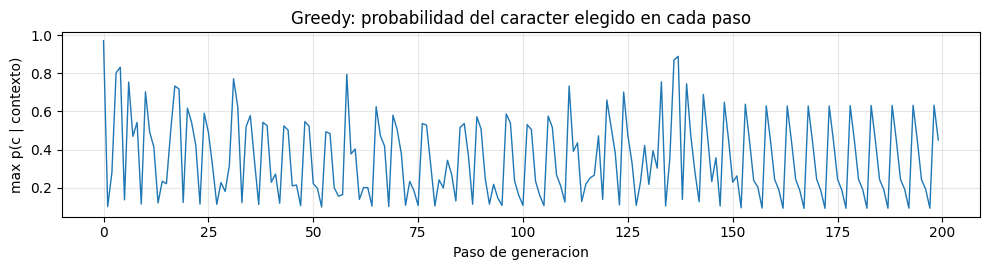

p media del argmax: 0.357 | pasos con p < 0.5: 143


In [15]:
g = samples['A'][0][len(PROMPT):]
print('Las 5 muestras greedy son identicas:', len(set(samples['A'])) == 1)
words = g.split(); cnt = Counter(words)
print(f'Muestra A1: {len(words)} palabras, {len(cnt)} distintas. Mas frecuentes: {cnt.most_common(6)}')

# Se extiende la generacion greedy a 1000 caracteres para ver si el texto se vuelve exactamente periodico
g_long = generate(PROMPT, 1000, 'greedy')[len(PROMPT):]
L, reps = repeat_period(g_long, min_reps=3)
if L:
    start = next(i for i in range(len(g_long)) if all(g_long[j] == g_long[j + L] for j in range(i, len(g_long) - L)))
    print(f'Con 1000 caracteres, greedy entra a un ciclo EXACTO de periodo {L} desde el caracter {start}:')
    print(repr(g_long[start:start + L]))
else:
    print('No se detecto un ciclo exacto en 1000 caracteres.')

# Probabilidad del caracter elegido (el argmax) en cada paso del camino greedy
pmax = [float(softmax(lg).max()) for lg in sample_logits['A'][0]]
plt.figure(figsize=(10, 2.8))
plt.plot(pmax, lw=1)
plt.xlabel('Paso de generacion'); plt.ylabel('max p(c | contexto)')
plt.title('Greedy: probabilidad del caracter elegido en cada paso')
plt.grid(alpha=0.3); plt.tight_layout(); plt.savefig('greedy_pmax.png', dpi=150); plt.show()
print(f'p media del argmax: {np.mean(pmax):.3f} | pasos con p < 0.5: {sum(p < 0.5 for p in pmax)}')

**Respuesta 2.2 (a).** El muestreo greedy elige en cada paso $c_{t+1} = \arg\max_i\, p_\theta(i \mid c_{t-127}, \dots, c_t)$. De esa definición salen las cuatro causas del comportamiento observado:

1. **Es determinista.** Las cinco muestras A1–A5 son idénticas carácter por carácter, porque no hay ninguna fuente de aleatoriedad: la salida es una función fija del prompt.
2. **Una función determinista sobre un espacio finito termina en un ciclo.** El siguiente carácter depende solo de los últimos 128 caracteres, y ese contexto vive en un conjunto finito. En cuanto un contexto se repite, todo lo que sigue se repite (principio del palomar). En nuestra muestra el ciclo aparece dentro de los mismos 200 caracteres: **a partir del carácter 140 el texto es la cadena `thee ` repetida, un ciclo exacto de periodo 5**. De 44 palabras solo 10 son distintas: `thee` aparece 18 veces y `the` 14 (el 73 % de las palabras), y distinct-4 es 0.223 contra 0.77–0.98 de las demás configuraciones.
3. **La forma de la distribución.** A nivel de carácter la distribución es bastante plana: el argmax tiene en promedio probabilidad 0.357, y en 143 de los 200 pasos es menor que 0.5. Greedy descarta en cada paso ~64 % de la masa, y siempre en la misma dirección: hacia los patrones más frecuentes del corpus (`e`, espacio, `th`). Así se forma un atractor: después de `thee ` el carácter más probable es `t`, luego `h`, `e`, `e` y otra vez el espacio. Además, una vez que la repetición llena el contexto, la atención puede copiar patrones recientes, lo que hace la repetición aún más probable y la refuerza.
4. **El máximo local no es una muestra típica.** El texto real tiene ~2.89 bits de entropía por carácter (la pérdida de validación); greedy produce 0 bits por carácter. Elegir siempre el carácter más probable no genera una secuencia que se parezca al texto real.

### (b) Top-k: efecto de $k$ y de $\tau$

Para separar los dos efectos se mide, sobre los mismos contextos (los de las muestras C), la entropía de la distribución completa a $\tau = 0.7$ y $\tau = 1.0$, y la fracción de masa que queda fuera del top-5.

In [16]:
H07, H10, mass_out5_07, mass_out5_10, mass_out50 = [], [], [], [], []
for lg_list in sample_logits['C']:
    for lg in lg_list:
        p07, p10 = softmax(lg / 0.7), softmax(lg / 1.0)
        H07.append(entropy_bits(p07)); H10.append(entropy_bits(p10))
        mass_out5_07.append(1 - float(torch.topk(p07, 5).values.sum()))
        mass_out5_10.append(1 - float(torch.topk(p10, 5).values.sum()))
        mass_out50.append(1 - float(torch.topk(p10, 50).values.sum()))
print(f'Entropia de la distribucion completa: tau=0.7 -> {np.mean(H07):.3f} bits | tau=1.0 -> {np.mean(H10):.3f} bits')
print(f'Masa fuera del top-5:  tau=0.7 -> {np.mean(mass_out5_07):.4f} | tau=1.0 -> {np.mean(mass_out5_10):.4f}')
print(f'Masa fuera del top-50 (tau=1.0): {np.mean(mass_out50):.2e}')

# Ejemplo concreto: como cambia la distribucion en un contexto
ctx = 'ROMEO:\nI will '
lg = model(torch.tensor([encode(ctx)], device=device))[0, -1].detach().cpu()
for tau in (0.7, 1.0):
    pr = softmax(lg / tau); top = torch.topk(pr, 6)
    print(f'tau={tau}: ' + ', '.join(f'{itos[int(i)]!r}:{float(v):.3f}' for v, i in zip(top.values, top.indices)))

# Palabras inventadas en B vs C
for cfg in ('B', 'C'):
    words = [w.strip(".,;:!?'-\"").lower() for t in samples[cfg] for w in t[len(PROMPT):].split()]
    fake = sorted(set(w for w in words if w and w not in train_words))
    print(f'{cfg}: {len(fake)} palabras que no existen en el corpus -> {fake[:15]}')

Entropia de la distribucion completa: tau=0.7 -> 2.188 bits | tau=1.0 -> 2.896 bits
Masa fuera del top-5:  tau=0.7 -> 0.1404 | tau=1.0 -> 0.2371
Masa fuera del top-50 (tau=1.0): 6.14e-04
tau=0.7: 't':0.149, 's':0.109, 'a':0.104, 'h':0.098, 'm':0.079, 'w':0.077
tau=1.0: 't':0.109, 's':0.088, 'a':0.085, 'h':0.081, 'm':0.070, 'w':0.069
B: 61 palabras que no existen en el corpus -> ['alline', 'ang', 'ar', 'ard', 'armes', 'arte', 'beaced', 'bucinio', 'dot', 'hee', 'hend', 'honer', 'hough', 'lis', 'madint']
C: 98 palabras que no existen en el corpus -> ['alfte', 'amake', 'amble', 'ands', 'anves', 'ascienc', 'b', "bat'ter", 'beardind', 'beetlioze', 'blak', 'brucas', 'brucenck', 'buby', 'calus']


**Respuesta 2.2 (b).** De la fórmula, $\dfrac{P(w_i)}{P(w_j)} = \exp\!\left(\dfrac{z_i - z_j}{\tau}\right)$, es decir, $q_i \propto p_i^{1/\tau}$.

**Efecto de $k$ (5 → 50): controla el soporte.** A $\tau = 1.0$, quedarse con el top-5 deja fuera en promedio el 23.7 % de la masa (14.0 % a $\tau = 0.7$). Con $k = 50$ se descarta apenas el 0.061 %: con un vocabulario de 65 caracteres, $k = 50$ casi no trunca, y C equivale prácticamente a muestrear del modelo completo. Ampliar el soporte aumenta la diversidad: distinct-4 sube de 0.827 (B) a 0.981 (C) y la entropía efectiva por paso de 1.53 a 2.89 bits. Pero la cola es también donde viven los caracteres improbables o erróneos: B produce 61 palabras inexistentes en el corpus y C 98.

**Efecto de $\tau$ (0.7 → 1.0): controla la concentración.** Con $\tau < 1$ las diferencias entre logits se multiplican por $1/\tau \approx 1.43$, lo que concentra la masa en los caracteres más probables. En los mismos contextos, la entropía de la distribución completa es de 2.19 bits a $\tau = 0.7$ y de 2.90 bits a $\tau = 1.0$. Por ejemplo, tras `ROMEO:\nI will ` la probabilidad de `t` baja de 0.149 a 0.109 al pasar de $\tau = 0.7$ a $1.0$, y la masa se reparte hacia la cola.

En B los dos parámetros concentran; en C los dos dispersan.

- **B es la más coherente:** 65.7 % de palabras reales contra 46.5 %. Por ejemplo, B4: *"That are of his haver of tould thou hat him,"*. El costo es que hereda algo de la repetitividad de greedy: `sould` aparece en B2, B3 y B4, `shat` en B3, B4 y B5, y `stourd` en B1 y B5.
- **C es la más creativa:** inventa palabras (`beetlioze`, `beardind`, `ascienc`) y nombres de personajes (`LAREHAANIUS`, `BRUCAS`, `BRUCENCK`), varía más la puntuación y cambia de hablante con más frecuencia: C5 pasa por GLUDW, BRUCENCK y JUEO en 200 caracteres. Pero menos de la mitad de sus palabras existen.

Ninguna es coherente a nivel de significado: con perplejidad 7.4 el modelo aprendió ortografía de palabras frecuentes y el formato del diálogo, no sentido. (La configuración D, top-p 0.70 con $\tau = 0.7$, logra 74.9 % de palabras reales, la cifra más alta después de greedy.)

### (c) Top-p adaptativo (configuración E): ¿dónde está seguro y dónde no?

Para cada paso de las 5 muestras E se registra el tamaño del núcleo ($p = 0.95$, $\tau = 1$). Un núcleo de 1 o 2 caracteres significa que el modelo está casi seguro; un núcleo grande significa incertidumbre.

MAS SEGURO (nucleo minimo, mayor p_max):
  E4 paso 171 | nucleo= 1 | p_max=0.995 | ...' nom bedsess.\n\nFRUCECENI:' -> '\n'
  E1 paso  90 | nucleo= 1 | p_max=0.994 | ...' that my gary.\n\nMABELAST:' -> '\n'
  E2 paso 114 | nucleo= 1 | p_max=0.989 | ...'groyser:\nSo tonciongs, yo' -> 'u'
  E5 paso  64 | nucleo= 1 | p_max=0.987 | ...'ould pies\nMeechilin it yo' -> 'u'
  E3 paso 102 | nucleo= 1 | p_max=0.986 | ...'frembe;\nLood for hick, yo' -> 'u'
  E3 paso 144 | nucleo= 1 | p_max=0.983 | ...'m withess,\nAnd me tour yo' -> 'u'
  E2 paso 184 | nucleo= 1 | p_max=0.982 | ...'ocknges any.\nWhill at, yo' -> 'u'
  E5 paso  92 | nucleo= 1 | p_max=0.982 | ...'and will my meld honer yo' -> 'u'

MAS INSEGURO (nucleo maximo):
  E4 paso  50 | nucleo=36 | p_max=0.117 | ...' the sereand\nBut ad. Bat ' -> 't'
  E2 paso  49 | nucleo=36 | p_max=0.162 | ..."'s fellous heart, at thy\n" -> 'T'
  E4 paso  77 | nucleo=35 | p_max=0.113 | ...'eath ather, do noot may! ' -> 't'
  E5 paso 100 | nucleo=35 | p_max=0

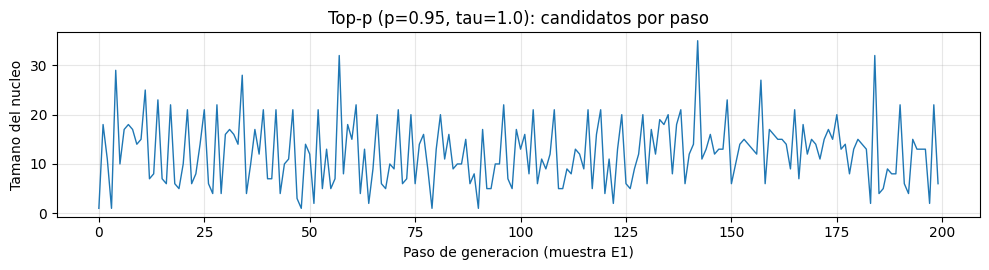

Nucleo: media 12.58, mediana 12, min 1, max 36


In [17]:
records = []   # (muestra, posicion, tamano_nucleo, p_max, contexto, caracter_generado)
for s, (txt, lg_list) in enumerate(zip(samples['E'], sample_logits['E']), 1):
    for t, lg in enumerate(lg_list):
        pos = len(PROMPT) + t
        records.append((s, t, nucleus_size(lg, 0.95, 1.0), float(softmax(lg).max()),
                        txt[max(0, pos - 25):pos], txt[pos]))

def show(r):
    s, t, ns, pm, ctx, ch = r
    return f'E{s} paso {t:3d} | nucleo={ns:2d} | p_max={pm:.3f} | ...{ctx!r} -> {ch!r}'

by_size = sorted(records, key=lambda r: (r[2], -r[3]))
print('MAS SEGURO (nucleo minimo, mayor p_max):')
for r in by_size[:8]: print('  ' + show(r))
print('\nMAS INSEGURO (nucleo maximo):')
for r in by_size[-8:][::-1]: print('  ' + show(r))
mid = [r for r in records if r[4] and r[4][-1].isalpha() and r[2] <= 2]
print('\nDENTRO DE UNA PALABRA con nucleo <= 2:')
for r in sorted(mid, key=lambda r: -r[3])[:6]: print('  ' + show(r))

# Agregado por tipo de posicion (segun el caracter anterior)
def pos_type(ctx):
    prev = ctx[-1] if ctx else '\n'
    if prev == '\n': return 'inicio de linea'
    if prev == ' ': return 'tras un espacio (inicio de palabra)'
    if prev in '.,;:!?': return 'tras puntuacion'
    return 'dentro de una palabra'

agg = {}
for r in records:
    agg.setdefault(pos_type(r[4]), []).append(r[2])
print('\nTamano medio del nucleo por tipo de posicion:')
for k, v in sorted(agg.items(), key=lambda kv: np.mean(kv[1])):
    print(f'  {k:<36} {np.mean(v):5.2f} candidatos  (n={len(v)}, % con nucleo=1: {100*np.mean(np.array(v)==1):.0f}%)')

ns = [r[2] for r in records]
plt.figure(figsize=(10, 2.8))
plt.plot([r[2] for r in records if r[0] == 1], lw=1)
plt.xlabel('Paso de generacion (muestra E1)'); plt.ylabel('Tamano del nucleo')
plt.title('Top-p (p=0.95, tau=1.0): candidatos por paso')
plt.grid(alpha=0.3); plt.tight_layout(); plt.savefig('nucleo_E1.png', dpi=150); plt.show()
print(f'Nucleo: media {np.mean(ns):.2f}, mediana {np.median(ns):.0f}, min {min(ns)}, max {max(ns)}')

**Respuesta 2.2 (c)** *(en el enunciado aparece como un segundo "a").* En la configuración E el tamaño del núcleo varía de **1 a 36 candidatos** (media 12.6, mediana 12), así que el muestreo realmente se adapta paso a paso.

**Momentos de alta seguridad (núcleo = 1):**

- **Después del nombre del personaje y los dos puntos → salto de línea.** E4 `FRUCECENI:` → `\n` con $p = 0.995$ y E1 `MABELAST:` → `\n` (0.994). El formato `NOMBRE:\n` es el patrón más regular del corpus, y el modelo está seguro aun cuando el nombre que acaba de inventar no existe. En general, tras un signo de puntuación el núcleo tiene 1.59 candidatos en promedio, y el 41 % de las veces es de tamaño 1.
- **Al completar palabras muy frecuentes.** `yo` → `u` ocupa seis de los ocho pasos más seguros de todas las muestras, por ejemplo E2 `So tonciongs, yo` → `u` (0.989), E5 `Meechilin it yo` → `u` (0.987) y E3 `Lood for hick, yo` → `u` (0.986). El modelo completa `you` con certeza aunque las palabras anteriores no existan.

**Momentos de alta inseguridad:**

- **Inicio de línea.** E2 `...at thy\n` → `T` con 36 candidatos ($p_{max} = 0.162$); E5 `...your bete\n` → `M` con 35 (0.170). En promedio, al inicio de línea hay 24.7 candidatos y el núcleo nunca es de tamaño 1.
- **Inicio de palabra, después de un espacio.** E4 `Bat ` → `t` con 36 candidatos ($p_{max} = 0.117$); E4 `do noot may! ` → `t` con 35 (0.113). Promedio de 22.3, nunca 1.
- **Inicio de oración.** E4 `FRUCECENI:\nLood. ` → `H` con 34 candidatos y $p_{max} = 0.094$, la probabilidad máxima más baja entre los pasos más inseguros.

**Patrón general.** El modelo está seguro en las decisiones ortográficas y de formato, que quedan determinadas por los caracteres inmediatamente anteriores (completar una palabra frecuente, poner el salto de línea después de `NOMBRE:`). Está inseguro donde se decide **qué palabra viene** (inicio de palabra, de verso o de oración), que es la decisión de contenido. Dentro de las palabras el promedio es de 10.6 candidatos: solo las palabras muy frecuentes se completan con certeza.

Top-p aprovecha esto: se comporta como greedy donde el modelo está seguro y se abre a más de 30 opciones donde hay muchas continuaciones válidas. Un $k$ fijo no puede hacer ambas cosas: $k = 5$ recortaría opciones legítimas al inicio de línea, y $k = 50$ deja pasar cola donde el modelo ya está seguro.